In [2]:
!pip install accelerate -U

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 2.9 MB/s eta 0:00:00a 0:00:01


In [4]:
!pip install nltk
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.3 MB/s eta 0:00:00a 0:00:01
  Using cached click-8.3.1-py3-none-any.whl (108 kB)


[nltk_data] Downloading package punkt_tab to /bigdata/userhome/student
[nltk_data]     s/md5_sd7aa1b0bd2cf032768f024455ba/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt to /bigdata/userhome/students/md
[nltk_data]     5_sd7aa1b0bd2cf032768f024455ba/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

/bigdata/userhome/students/md5_sd7aa1b0bd2cf032768f024455ba/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Se încarcă datele traduse...
Se încarcă modelul: paraphrase-multilingual-MiniLM-L12-v2...
Exemplu text RO: Rețetă: Miso-Butter Friptura de pui cu Acorn Squash Panzanella. Ingrediente: 1 (31⁄2! - pound) found chicken ... 23⁄4 teaspoon kosher sare, divizată,  ...
Se generează vectorii (embeddings) pentru limba română...


Batches: 100%|██████████| 422/422 [00:09<00:00, 46.42it/s]



--- Rezultate Căutare Semantică (Română) ---
User: 'Vreau un tort de ciocolată delicios'
 -> Recomandare: 'Prăjitură cu ciocolată și fructe de pasiune'
 -> Categorie: Desert (Așteptat: Desert)

User: 'Ceva dulce cu căpșuni'
 -> Recomandare: 'Big-Batch Strawberry Compote'
 -> Categorie: Altele (Așteptat: Desert)

User: 'Pui prăjit crocant'
 -> Recomandare: 'Dependența de ridichi'
 -> Categorie: Altele (Așteptat: Carne/Sărat)

User: 'O salată verde sănătoasă'
 -> Recomandare: 'Salată verde cu frunze, rodie şi salată de migdale'
 -> Categorie: Vegetarian/Salate (Așteptat: Vegetarian/Salate)

User: 'Paste cremoase carbonara'
 -> Recomandare: 'Orrechiette Carbonara'
 -> Categorie: Paste/Făinoase (Așteptat: Paste/Făinoase)

User: 'Biscuiți fără gluten cu migdale'
 -> Recomandare: 'Biscuiți fără gluten'
 -> Categorie: Desert (Așteptat: Desert)

User: 'Tocăniță picantă de vită'
 -> Recomandare: 'Halote în piele cu roșcove încețoșate'
 -> Categorie: Altele (Așteptat: Carne/Sărat)

Se calculeaz

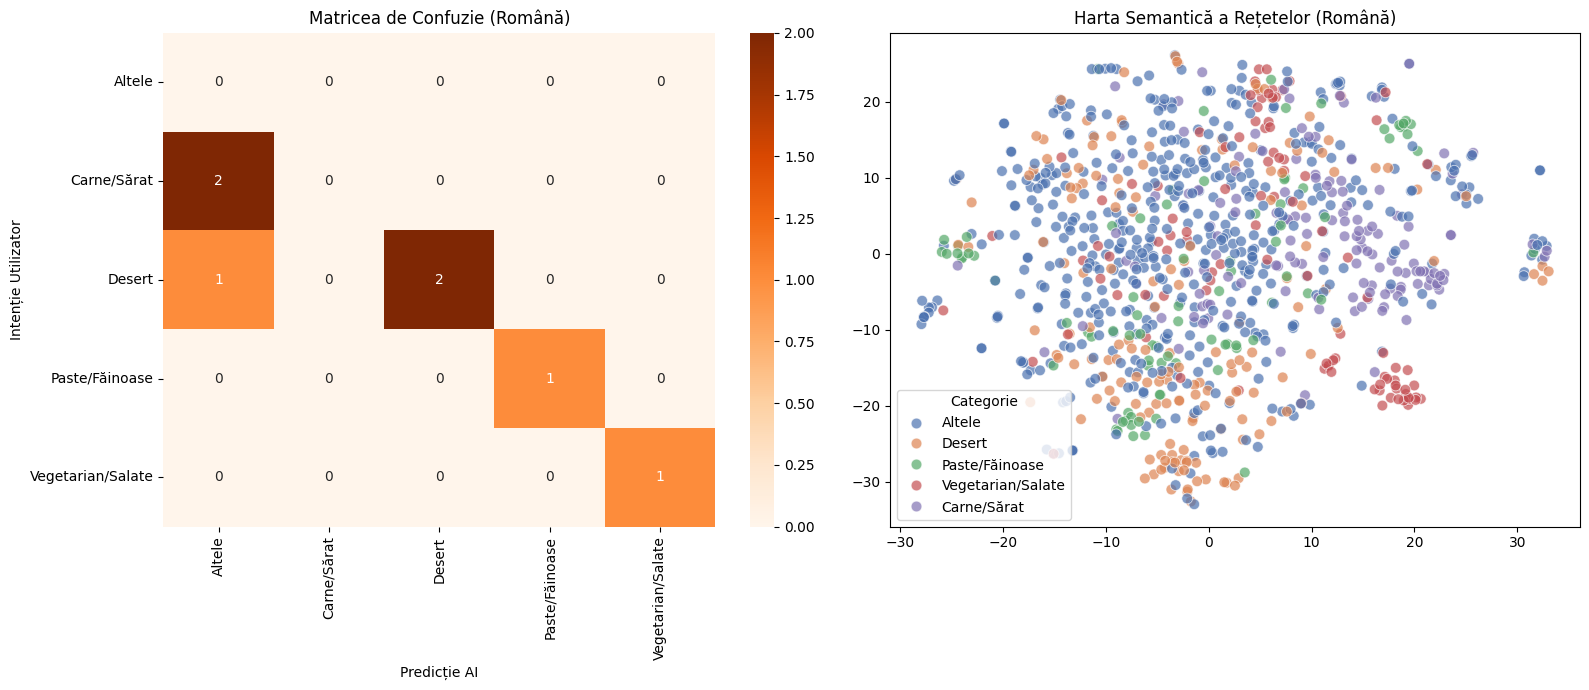

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer, util, InputExample, losses
from torch.utils.data import DataLoader
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
import ast

# ==========================================
# 1. ÎNCĂRCAREA DATELOR TRADUSE
# ==========================================
print("Se încarcă datele traduse...")
# Asigură-te că fișierul generat anterior este aici
df = pd.read_csv("recipes_translated_fast.csv") 

# Curățare: Eliminăm rândurile goale
df = df.dropna(subset=['Title', 'Ingredients', 'Instructions'])

# Dacă ai nevoie de curățarea listei de ingrediente (care acum e string tradus)
def clean_ingredients_ro(ing_str):
    # Încercăm să scoatem parantezele de listă dacă au rămas de la traducere
    return str(ing_str).replace('[', '').replace(']', '').replace("'", "")

df['Cleaned_Ingredients_Ro'] = df['Ingredients'].apply(clean_ingredients_ro)

# ==========================================
# 2. SELECTAREA MODELULUI (ROMÂNĂ / MULTILINGV)
# ==========================================
# Pentru limba română și similaritate semantică, cel mai bun model "ready-to-go" este:
# 'paraphrase-multilingual-MiniLM-L12-v2' (foarte rapid și precis pe RO)
# SAU 'dumitrescu/bert-base-romanian-cased-v1' (dar acesta trebuie adaptat pentru sentence embeddings).

# Voi folosi standardul de aur pentru semantic search multilingv, care include româna la nivel nativ:
model_name = 'paraphrase-multilingual-MiniLM-L12-v2' 
print(f"Se încarcă modelul: {model_name}...")
model = SentenceTransformer(model_name)

# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================
def create_combined_features_ro(row):
    # Combinăm titlul cu ingredientele pentru context
    # Instrucțiunile le scurtăm
    instr = str(row['Instructions']).replace('\n', ' ')[:300]
    return f"Rețetă: {row['Title']}. Ingrediente: {row['Cleaned_Ingredients_Ro']}. Preparare: {instr}"

df['combined_features_ro'] = df.apply(create_combined_features_ro, axis=1)

print("Exemplu text RO:", df['combined_features_ro'].iloc[0][:150], "...")

# ==========================================
# 4. (OPȚIONAL) FINE-TUNING / ANTRENARE
# ==========================================
# Dacă vrei să "specializezi" modelul pe rețetele tale (să învețe specificul culinar românesc din dataset),
# poți face o antrenare scurtă nesupervizată (SimCSE sau TSDAE).
# Dacă doar vrei să îl folosești, poți sări peste acest pas. 
# Codul de mai jos e pentru antrenare (decomentează dacă vrei să rulezi antrenarea efectivă).

"""
print("Pregătire date pentru Fine-Tuning (Denoising AutoEncoder)...")
train_sentences = df['combined_features_ro'].tolist()
train_data = [InputExample(texts=[s]) for s in train_sentences]
train_dataloader = DataLoader(train_data, batch_size=8, shuffle=True)
train_loss = losses.MultipleNegativesRankingLoss(model) # Loss puternic pentru semantică

# Antrenare (1 epocă e de obicei suficient pentru adaptare la domeniu)
# model.fit(train_objectives=[(train_dataloader, train_loss)], epochs=1, show_progress_bar=True)
# print("Fine-tuning complet!")
"""

# ==========================================
# 5. GENERARE EMBEDDINGS
# ==========================================
print("Se generează vectorii (embeddings) pentru limba română...")
recipe_embeddings = model.encode(df['combined_features_ro'].tolist(), convert_to_tensor=True, show_progress_bar=True)

# ==========================================
# 6. ETICHETARE AUTOMATĂ (PENTRU GRAFICE)
# ==========================================
# Adaptăm funcția de categorie pentru limba română
def get_heuristic_category_ro(row):
    text = (str(row['Title']) + " " + str(row['Cleaned_Ingredients_Ro'])).lower()
    
    if any(x in text for x in ['pui', 'vită', 'porc', 'friptură', 'carne', 'cârnați']):
        return 'Carne/Sărat'
    elif any(x in text for x in ['ciocolată', 'tort', 'prăjitură', 'biscuiți', 'zahăr', 'dulce', 'desert', 'plăcintă']):
        return 'Desert'
    elif any(x in text for x in ['salată', 'legume', 'supă', 'morcov', 'cartof']):
        return 'Vegetarian/Salate'
    elif any(x in text for x in ['paste', 'orez', 'spaghete', 'făină', 'pâine']):
        return 'Paste/Făinoase'
    else:
        return 'Altele'

df['Categorie_Auto'] = df.apply(get_heuristic_category_ro, axis=1)

# ==========================================
# 7. EVALUARE: Teste de Similaritate în Română
# ==========================================
test_queries_ro = [
    ("Vreau un tort de ciocolată delicios", "Desert"),
    ("Ceva dulce cu căpșuni", "Desert"),
    ("Pui prăjit crocant", "Carne/Sărat"),
    ("O salată verde sănătoasă", "Vegetarian/Salate"),
    ("Paste cremoase carbonara", "Paste/Făinoase"),
    ("Biscuiți fără gluten cu migdale", "Desert"),
    ("Tocăniță picantă de vită", "Carne/Sărat")
]

true_labels = []
predicted_labels = []

print("\n--- Rezultate Căutare Semantică (Română) ---")
for query, expected_cat in test_queries_ro:
    query_vec = model.encode(query, convert_to_tensor=True)
    
    # Calculăm similaritatea
    cos_scores = util.cos_sim(query_vec, recipe_embeddings)[0]
    best_match_idx = np.argmax(cos_scores.cpu().numpy())
    
    # Rezultate
    pred_cat = df.iloc[best_match_idx]['Categorie_Auto']
    pred_title = df.iloc[best_match_idx]['Title']
    
    true_labels.append(expected_cat)
    predicted_labels.append(pred_cat)
    
    print(f"User: '{query}'\n -> Recomandare: '{pred_title}'\n -> Categorie: {pred_cat} (Așteptat: {expected_cat})\n")

# ==========================================
# 8. VIZUALIZARE
# ==========================================
labels = sorted(list(set(true_labels) | set(predicted_labels)))
cm = confusion_matrix(true_labels, predicted_labels, labels=labels)

plt.figure(figsize=(16, 7))

# Grafic 1: Matricea
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Oranges')
plt.title('Matricea de Confuzie (Română)')
plt.xlabel('Predicție AI')
plt.ylabel('Intenție Utilizator')

# Grafic 2: t-SNE
# Luăm subset pentru viteză
sample_indices = np.random.choice(len(df), min(1000, len(df)), replace=False)
embeddings_subset = recipe_embeddings[sample_indices].cpu().numpy()
categories_subset = df['Categorie_Auto'].iloc[sample_indices].values

print("Se calculează t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
embeddings_2d = tsne.fit_transform(embeddings_subset)

plt.subplot(1, 2, 2)
sns.scatterplot(
    x=embeddings_2d[:, 0], 
    y=embeddings_2d[:, 1], 
    hue=categories_subset, 
    palette='deep',
    s=60,
    alpha=0.7
)
plt.title('Harta Semantică a Rețetelor (Română)')
plt.legend(title='Categorie')

plt.tight_layout()
plt.show()

In [ ]:
import os
# --- FIX FINAL: FORȚĂM CPU ---
# Această linie "ascunde" placa video, obligând scriptul să ruleze pe procesor.
# Astfel evităm complet eroarea de driver CUDA.
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import pandas as pd
from sentence_transformers import SentenceTransformer, models, losses
from sentence_transformers.datasets import DenoisingAutoEncoderDataset
from torch.utils.data import DataLoader
import logging
import torch

# ==========================================
# 1. CONFIGURARE
# ==========================================
logging.basicConfig(format='%(asctime)s - %(message)s',
                    datefmt='%Y-%m-%d %H:%M:%S',
                    level=logging.INFO)

model_name = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'

# Pe CPU putem crește batch_size înapoi la 8 sau 16 pentru viteză
batch_size = 8 
num_epochs = 3 
output_path = 'output/model-gatit-ro-v1'

print("Se folosește dispozitivul: CPU (Antrenarea va dura puțin mai mult, dar este stabilă)")

# ==========================================
# 2. ÎNCĂRCARE DATE
# ==========================================
print("Se încarcă dataset-ul tradus...")
df = pd.read_csv("recipes_translated_fast.csv")
df = df.dropna(subset=['Title', 'Ingredients', 'Instructions'])

def clean_text(row):
    ings = str(row['Ingredients']).replace('[', '').replace(']', '').replace("'", "")
    instr = str(row['Instructions']).replace('\n', ' ')
    return f"{row['Title']} {ings} {instr}"

train_sentences = df.apply(clean_text, axis=1).tolist()
print(f"Număr de rețete: {len(train_sentences)}")

# ==========================================
# 3. CONSTRUIRE MODEL
# ==========================================
word_embedding_model = models.Transformer(model_name)
pooling_model = models.Pooling(word_embedding_model.get_word_embedding_dimension(), 'mean')
model = SentenceTransformer(modules=[word_embedding_model, pooling_model])

train_dataset = DenoisingAutoEncoderDataset(train_sentences)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

train_loss = losses.DenoisingAutoEncoderLoss(model, decoder_name_or_path=model_name, tie_encoder_decoder=True)

# ==========================================
# 4. ANTRENARE
# ==========================================
print(f"Începe antrenarea...")

model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=num_epochs,
    weight_decay=0,
    scheduler='constantlr',
    optimizer_params={'lr': 3e-5},
    show_progress_bar=True,
    output_path=output_path
)

print(f"\nAntrenare completă! Modelul este salvat în: {output_path}")

/bigdata/userhome/students/md5_sd7aa1b0bd2cf032768f024455ba/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Se folosește dispozitivul: CPU (Antrenarea va dura puțin mai mult, dar este stabilă)
Se încarcă dataset-ul tradus...
Număr de rețete: 13501


2026-01-02 15:27:54 - Use pytorch device_name: cpu
2026-01-02 15:27:54 - When tie_encoder_decoder=True, the decoder_name_or_path will be invalid.
Some weights of BertLMHeadModel were not initialized from the model checkpoint at sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 and are newly initialized: ['bert.encoder.layer.0.crossattention.output.LayerNorm.bias', 'bert.encoder.layer.0.crossattention.output.LayerNorm.weight', 'bert.encoder.layer.0.crossattention.output.dense.bias', 'bert.encoder.layer.0.crossattention.output.dense.weight', 'bert.encoder.layer.0.crossattention.self.key.bias', 'bert.encoder.layer.0.crossattention.self.key.weight', 'bert.encoder.layer.0.crossattention.self.query.bias', 'bert.encoder.layer.0.crossattention.self.query.weight', 'bert.encoder.layer.0.crossattention.self.value.bias', 'bert.encoder.layer.0.crossattention.self.value.weight', 'bert.encoder.layer.1.crossattention.output.LayerNorm.bias', 'bert.encoder.layer.1.crossattention.output.LayerNo

Începe antrenarea...


/bigdata/userhome/students/md5_sd7aa1b0bd2cf032768f024455ba/venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


Step,Training Loss
500,7.130300
1000,4.569100
1500,3.824300
2000,3.461000
2500,3.249100
3000,3.068700
